# Лабораторная работа: скалярное автоматическое дифференцирование и обучение одного нейрона

Работа выполнена по методичке: `lab_guide.pdf`, теоретическая часть — в `theory.pdf`, разбор правила произведения — в `product_rule_debugging.pdf`. Ячейки выполняются сверху вниз.

**Выполнил:** Фролов А.А., 3 курс, группа ИВТ-2.3  
**Дисциплина:** Математика для ИИ, лабораторная работа №3

In [1]:
# AUTOGRAD_ESSENTIALS_CELL: imports_and_helper
import math


def assert_close(actual, expected, tolerance=1e-9):
    difference = abs(actual - expected)
    assert difference <= tolerance, (
        f"Ожидалось {expected}, получено {actual}, "
        f"абсолютная ошибка {difference}"
    )

## Подготовка

Код ячейки `imports_and_helper` перенесён из guide. Функция `assert_close` сравнивает вещественные числа с допуском, потому что для результатов `sin`, `exp` и `tanh` сравнение через `==` ненадёжно. Ячейка ничего не печатает — так и должно быть.

## Часть первая: класс Value

Ниже итоговый текст ячейки `value` из guide: каркас, сложение, умножение, отрицание, вычитание, степень, элементарные функции и метод `backward`. Каждая вершина графа хранит:

- `data` — число из прямого прохода;
- `grad` — накопленный градиент $g_v = \partial J/\partial v$;
- `parents` — ссылки на непосредственных родителей;
- `op` — метку операции (только для чтения графа);
- `_backward` — замыкание с локальным правилом цепочки.

In [2]:
# AUTOGRAD_ESSENTIALS_CELL: value
class Value:
    def __init__(self, data, parents=(), op=""):
        self.data = float(data)
        self.grad = 0.0
        self.parents = parents
        self.op = op
        self._backward = lambda: None

    def __repr__(self):
        return (
            f"Value(data={self.data:.6g}, grad={self.grad:.6g}, "
            f"op={self.op!r})"
        )

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        result = Value(
            self.data + other.data,
            parents=(self, other),
            op="+",
        )

        def backward():
            self.grad += result.grad
            other.grad += result.grad

        result._backward = backward
        return result

    __radd__ = __add__

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        result = Value(
            self.data * other.data,
            parents=(self, other),
            op="*",
        )

        def backward():
            self.grad += result.grad * other.data
            other.grad += result.grad * self.data

        result._backward = backward
        return result

    __rmul__ = __mul__

    def __neg__(self):
        result = Value(-self.data, parents=(self,), op="neg")

        def backward():
            self.grad += result.grad * (-1)

        result._backward = backward
        return result

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def __pow__(self, power):
        result = Value(
            self.data ** power,
            parents=(self,),
            op=f"pow({power})",
        )

        def backward():
            local_derivative = power * self.data ** (power - 1)
            self.grad += result.grad * local_derivative

        result._backward = backward
        return result

    def sin(self):
        result = Value(math.sin(self.data), parents=(self,), op="sin")

        def backward():
            self.grad += result.grad * math.cos(self.data)

        result._backward = backward
        return result

    def exp(self):
        result = Value(math.exp(self.data), parents=(self,), op="exp")

        def backward():
            self.grad += result.grad * result.data

        result._backward = backward
        return result

    def log(self):
        result = Value(math.log(self.data), parents=(self,), op="log")

        def backward():
            self.grad += result.grad * (1 / self.data)

        result._backward = backward
        return result

    def tanh(self):
        result = Value(math.tanh(self.data), parents=(self,), op="tanh")

        def backward():
            self.grad += result.grad * (1 - result.data ** 2)

        result._backward = backward
        return result

    def backward(self):
        topo = []
        visited = set()

        def build(node):
            if node not in visited:
                visited.add(node)
                for parent in node.parents:
                    build(parent)
                topo.append(node)

        build(self)
        for node in topo:
            node.grad = 0.0
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

Проверка каркаса из guide: новый лист хранит `data = 2.0`, `grad = 0.0`, пустой кортеж родителей и пустую метку операции.

In [3]:
# проверка каркаса Value
first_value = Value(2)
assert first_value.data == 2.0
assert first_value.grad == 0.0
assert first_value.parents == ()
assert first_value.op == ""
print(first_value)

Value(data=2, grad=0, op='')


## Прямой проход: сложение

Для $z = x + y$ локальные производные $\dfrac{\partial z}{\partial x} = 1$, $\dfrac{\partial z}{\partial y} = 1$, поэтому в `backward` сложения оба родителя просто получают `result.grad`: $\Delta g_x^{(z)} = g_z$, $\Delta g_y^{(z)} = g_z$.

In [4]:
# AUTOGRAD_ESSENTIALS_CELL: addition_experiment
left = Value(2.5)
right = Value(-1.0)
sum_value = left + right
assert_close(sum_value.data, 1.5)
assert sum_value.parents == (left, right)
assert sum_value.op == "+"
print("Сложение в прямом проходе: OK")

Сложение в прямом проходе: OK


$2.5 + (-1.0) = 1.5$, у результата `parents == (left, right)` и метка `"+"`. Градиенты пока не считались — `backward` проверим позже.

## Прямой проход: умножение

Для $z = xy$: $\dfrac{\partial z}{\partial x} = y$, $\dfrac{\partial z}{\partial y} = x$. Значит, градиент по `self` умножается на `other.data`, а по `other` — на `self.data`: $\Delta g_x^{(z)} = g_z y$, $\Delta g_y^{(z)} = g_z x$. Например, при $x = 2$, $y = -3$, $g_z = 4$ получаем $\Delta g_x = -12$ и $\Delta g_y = 8$.

In [5]:
# AUTOGRAD_ESSENTIALS_CELL: multiplication_experiment
left = Value(4.0)
right = Value(-0.5)
product_value = left * right
scaled_value = 3.0 * left
assert_close(product_value.data, -2.0)
assert_close(scaled_value.data, 12.0)
assert product_value.parents == (left, right)
assert product_value.op == "*"
print("Умножение в прямом проходе: OK")

Умножение в прямом проходе: OK


$4 \cdot (-0.5) = -2$ и $3 \cdot 4 = 12$. Второй случай `3.0 * left` работает через `__rmul__`: у числа `float` нет умножения на `Value`, поэтому Python вызывает `left.__rmul__(3.0)`, и число превращается в константный лист `Value(3.0)`.

## Прямой проход: отрицание, вычитание и степень

- Отрицание $z = -x$: $\dfrac{dz}{dx} = -1$, вклад $\Delta g_x = -g_z$.
- Вычитание отдельного правила не имеет: $x - y = x + (-y)$, то есть строятся вершины `neg` и `+`.
- Степень $z = x^p$ с постоянным $p$: $\dfrac{dz}{dx} = p x^{p-1}$. Для `source = 3` и $p = 3$ локальная производная равна $3 \cdot 3^2 = 27$.

In [6]:
# AUTOGRAD_ESSENTIALS_CELL: neg_sub_power_experiment
source = Value(3.0)
negative = -source
difference = 5.0 - source
cube = source ** 3
assert_close(negative.data, -3.0)
assert_close(difference.data, 2.0)
assert_close(cube.data, 27.0)
assert negative.op == "neg"
assert cube.op == "pow(3)"
print("Отрицание, вычитание и степень в прямом проходе: OK")

Отрицание, вычитание и степень в прямом проходе: OK


Получили $-3$, $5 - 3 = 2$ (через `__rsub__`: `5.0 + (-source)`) и $3^3 = 27$. Метка степени `pow(3)` хранит показатель, по нему градиент не считается.

## Прямой проход: элементарные функции

Локальные производные:

$$
\frac{d}{dx}\sin x = \cos x,\qquad
\frac{d}{dx}e^x = e^x = z,\qquad
\frac{d}{dx}\ln x = \frac1x\ (x > 0),\qquad
\frac{d}{dx}\tanh x = 1 - \tanh^2 x = 1 - z^2.
$$

Для `exp` и `tanh` удобно брать уже посчитанный `result.data`, а не считать функцию второй раз.

In [7]:
# AUTOGRAD_ESSENTIALS_CELL: elementary_experiment
angle = Value(0.0)
positive = Value(2.0)
activation_input = Value(0.7)
assert_close(angle.sin().data, 0.0)
assert_close(positive.exp().log().data, 2.0)
assert_close(activation_input.tanh().data, math.tanh(0.7))
print("Элементарные функции в прямом проходе: OK")

Элементарные функции в прямом проходе: OK


$\sin 0 = 0$, $\ln(e^2) = 2$, $\tanh 0.7 \approx 0.604368$. Все четыре функции работают в прямом проходе.

## Обратный проход и общий узел графа

**Вывод вручную.** Для $f(a) = a^2 + a$ производная $\dfrac{df}{da} = 2a + 1$, при $a = 2$ получаем $f = 6$ и $f'(2) = 5$.

Как это получается в графе: `objective = (a * a) + a`. Обратный проход идёт так:

1. `objective.grad = 1`;
2. сложение отдаёт $1$ в узел `a * a` и $1$ в `a` (первый вклад, `a.grad = 1`);
3. умножение `a * a` имеет `parents = (a, a)`, поэтому отдаёт два вклада $1 \cdot a.data = 2$ и ещё $2$: `a.grad = 1 + 2 + 2 = 5`.

`visited` кладёт `a` в `topo` один раз, но все три ребра к `a` остаются, и `+=` складывает три вклада.

In [8]:
# AUTOGRAD_ESSENTIALS_CELL: backward_shared_graph
a = Value(2.0)
objective = a * a + a
objective.backward()
assert_close(objective.data, 6.0)
assert_close(a.grad, 5.0)
assert_close(objective.grad, 1.0)
print("Обратный проход и накопление двух вкладов: OK")

Обратный проход и накопление двух вкладов: OK


Получили `a.grad = 5`, как и в ручном выводе. Если бы в локальных правилах стояло `=` вместо `+=`, последний вклад затёр бы предыдущие и вышло бы 4 или 1.

## Ручная трассировка локального обратного прохода

Граф из теории: $m = ab$, $s = m + a$, $J = \tanh(s)$ при $a = 0.5$, $b = 1$.

**Прямой проход:** $m = 0.5$, $s = 1$, $J = \tanh 1 \approx 0.761594$.

**Обратный проход вручную** (порядок $J \to s \to m$):

1. $g_s = g_J (1 - J^2) = 1 - 0.761594^2 \approx 0.419974$;
2. сложение: $g_m = g_s \cdot 1 \approx 0.419974$, первый вклад в $a$: $\Delta g_a^{(s)} \approx 0.419974$;
3. умножение: $\Delta g_a^{(m)} = g_m b \approx 0.419974$, $g_b = g_m a \approx 0.209987$.

Итог: $g_a = 0.419974 + 0.419974 \approx 0.839949$, $g_b \approx 0.209987$.

Проверка обычным дифференцированием: $\dfrac{\partial J}{\partial a} = (1 - \tanh^2(ab + a))(b + 1) = 0.419974 \cdot 2$, $\dfrac{\partial J}{\partial b} = (1 - \tanh^2(ab + a))\, a = 0.419974 \cdot 0.5$ — те же числа.

In [9]:
# AUTOGRAD_ESSENTIALS_CELL: manual_backward_trace
a = Value(0.5)
b = Value(1.0)
m = a * b
s = m + a
j = s.tanh()

for node in (a, b, m, s, j):
    node.grad = 0.0
j.grad = 1.0
expected_gs = 1.0 - j.data ** 2

j._backward()
assert_close(s.grad, expected_gs)
assert_close(m.grad, 0.0)
assert_close(a.grad, 0.0)
print("После J._backward():", "g_s =", s.grad)

s._backward()
assert_close(m.grad, expected_gs)
assert_close(a.grad, expected_gs)
print("После s._backward():", "g_m =", m.grad, "; первый вклад в g_a =", a.grad)

m._backward()
assert_close(a.grad, expected_gs * (1.0 + b.data))
assert_close(b.grad, expected_gs * a.data)
print("После m._backward():", "g_a =", a.grad, "; g_b =", b.grad)

После J._backward(): g_s = 0.41997434161402614
После s._backward(): g_m = 0.41997434161402614 ; первый вклад в g_a = 0.41997434161402614
После m._backward(): g_a = 0.8399486832280523 ; g_b = 0.20998717080701307


**Что видно по выводу.** После `J._backward()` градиент впервые появился только у $s$ ($0.419974$). После `s._backward()` впервые получили градиент $m$ и $a$ (по $0.419974$), но у $a$ это пока лишь часть: второй потомок $m$ ещё не обработан. После `m._backward()` у $a$ добавился второй вклад и стало $0.839949$, а $b$ впервые получил $0.209987$. Числа совпали с ручным выводом выше. Обычный `j.backward()` делает то же самое сам, в порядке `reversed(topo) = [J, s, m, b, a]`.

## Численная проверка центральной разностью

**Вывод вручную.** Для $f(x) = \sin x \cdot e^x + x^3$ по правилу произведения и правилу степени

$$
f'(x) = e^x \cos x + \sin x \, e^x + 3x^2 = e^x(\cos x + \sin x) + 3x^2.
$$

При $x = 0.37$: $e^{0.37} \approx 1.447735$, $\cos 0.37 \approx 0.932327$, $\sin 0.37 \approx 0.361615$, $3 \cdot 0.37^2 = 0.4107$, поэтому

$$
f'(0.37) \approx 1.447735 \cdot 1.293943 + 0.4107 \approx 2.283986.
$$

Численно сравниваем с $\dfrac{f(x+h) - f(x-h)}{2h}$ при $h = 10^{-6}$.

In [10]:
# AUTOGRAD_ESSENTIALS_CELL: finite_difference
def plain_function(x):
    return math.sin(x) * math.exp(x) + x ** 3


point = 0.37
step = 1e-6
input_value = Value(point)
objective = input_value.sin() * input_value.exp() + input_value ** 3
objective.backward()

numerical_gradient = (
    plain_function(point + step) - plain_function(point - step)
) / (2 * step)
absolute_error = abs(input_value.grad - numerical_gradient)

assert absolute_error < 1e-5, absolute_error
print("Градиент Value                :", input_value.grad)
print("Градиент разностью            :", numerical_gradient)
print("Абсолютная ошибка             :", absolute_error)

Градиент Value                : 2.2839857484831385
Градиент разностью            : 2.283985748363637
Абсолютная ошибка             : 1.195012977461829e-10


**Интерпретация.** `Value` дал $f'(0.37) \approx 2.2839857485$ — это совпадает с ручным выводом. Центральная разность дала $2.2839857483\ldots$, абсолютная ошибка порядка $10^{-10}$, что намного меньше порога $10^{-5}$. Здесь `input_value` используется в трёх местах (`sin`, `exp`, `** 3`), и все три вклада сложились в один `grad`. Член $e^x\cos x + \sin x\, e^x$ — это ровно правило произведения из `product_rule_debugging.pdf`: два вклада через вершины `sin` и `exp`. Центральная разность сама ничего не доказывает, но если бы потерялся вклад одной ветки, ошибка была бы не меньше $0.41$ (самый маленький из трёх вкладов — $3x^2 = 0.4107$), а не $10^{-10}$.

## Часть вторая: один нейрон с гиперболическим тангенсом

Модель: $z = wx + b$, $\hat y = \tanh(z)$. Вес $w$ задаёт наклон, смещение $b$ сдвигает границу, где $\hat y$ меняет знак (это точка $x = -b/w$). Оба параметра — объекты `Value`, иначе `backward` не посчитает для них градиенты. При каждом вызове `neuron(x)` создаются новые вершины `*`, `+` и `tanh`, а `weight` и `bias` остаются теми же объектами.

In [11]:
# AUTOGRAD_ESSENTIALS_CELL: tanh_neuron
class TanhNeuron:
    def __init__(self, weight, bias):
        self.weight = Value(weight)
        self.bias = Value(bias)

    def __call__(self, x):
        return (self.weight * x + self.bias).tanh()

    def parameters(self):
        return [self.weight, self.bias]

## Прямой проход нейрона

Вручную: при $w = 2$, $b = -1$, $x = 0.5$ получаем $z = 2 \cdot 0.5 - 1 = 0$ и $\hat y = \tanh 0 = 0$.

In [12]:
# AUTOGRAD_ESSENTIALS_CELL: neuron_forward_experiment
neuron = TanhNeuron(weight=2.0, bias=-1.0)
prediction = neuron(0.5)
assert_close(prediction.data, 0.0)
assert neuron.parameters() == [neuron.weight, neuron.bias]
print("Прямой проход одного нейрона: OK")

Прямой проход одного нейрона: OK


Прогноз равен $0$, то есть точка $x = 0.5$ лежит ровно на границе $x = -b/w = 0.5$. `parameters()` возвращает сами объекты `weight` и `bias`, а не копии чисел.

## Среднеквадратичная ошибка и проверка градиентов параметров

Данные: $x = [-3, -2, -1, 0, 1, 2]$, $y = [-1, -1, -1, -1, 1, 1]$, $n = 6$.

$$
L = \frac1n \sum_{i=1}^{n} (\hat y_i - y_i)^2,\qquad \hat y_i = \tanh(w x_i + b).
$$

**Вывод градиентов вручную.** По правилу цепочки для одного объекта: $\dfrac{\partial q_i}{\partial e_i} = 2e_i$, $\dfrac{\partial \hat y_i}{\partial z_i} = 1 - \hat y_i^2$, $\dfrac{\partial z_i}{\partial w} = x_i$, $\dfrac{\partial z_i}{\partial b} = 1$. Суммируем по всем объектам:

$$
\frac{\partial L}{\partial w} = \frac1n \sum_i 2(\hat y_i - y_i)(1 - \hat y_i^2)\, x_i,\qquad
\frac{\partial L}{\partial b} = \frac1n \sum_i 2(\hat y_i - y_i)(1 - \hat y_i^2).
$$

**Подставляем $w = b = 0$.** Тогда все $z_i = 0$, $\hat y_i = 0$, $1 - \hat y_i^2 = 1$:

- $L = \frac16 \sum y_i^2 = \frac66 = 1$;
- $\dfrac{\partial L}{\partial w} = -\frac26 \sum y_i x_i = -\frac13 (3 + 2 + 1 + 0 + 1 + 2) = -\frac93 = -3$;
- $\dfrac{\partial L}{\partial b} = -\frac26 \sum y_i = -\frac13 (-4 + 2) = \frac23 \approx 0.6667$.

In [13]:
# AUTOGRAD_ESSENTIALS_CELL: loss_and_gradient
INPUTS = [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0]
TARGETS = [-1.0, -1.0, -1.0, -1.0, 1.0, 1.0]


def mean_squared_loss(neuron, inputs, targets):
    total = Value(0.0)
    for input_number, target_number in zip(inputs, targets):
        prediction = neuron(input_number)
        error = prediction - target_number
        total = total + error ** 2
    return total * (1.0 / len(inputs))


def plain_loss(weight, bias, inputs, targets):
    total = 0.0
    for input_number, target_number in zip(inputs, targets):
        prediction = math.tanh(weight * input_number + bias)
        total += (prediction - target_number) ** 2
    return total / len(inputs)


gradient_neuron = TanhNeuron(weight=0.0, bias=0.0)
initial_loss = mean_squared_loss(gradient_neuron, INPUTS, TARGETS)
initial_loss.backward()

step = 1e-6
numerical_weight_gradient = (
    plain_loss(step, 0.0, INPUTS, TARGETS)
    - plain_loss(-step, 0.0, INPUTS, TARGETS)
) / (2 * step)
numerical_bias_gradient = (
    plain_loss(0.0, step, INPUTS, TARGETS)
    - plain_loss(0.0, -step, INPUTS, TARGETS)
) / (2 * step)

assert_close(initial_loss.data, 1.0)
assert_close(
    gradient_neuron.weight.grad,
    numerical_weight_gradient,
    tolerance=1e-5,
)
assert_close(
    gradient_neuron.bias.grad,
    numerical_bias_gradient,
    tolerance=1e-5,
)

print("Начальная ошибка:", initial_loss.data)
print("Градиент по весу:", gradient_neuron.weight.grad)
print("Градиент по смещению:", gradient_neuron.bias.grad)

Начальная ошибка: 1.0
Градиент по весу: -3.0
Градиент по смещению: 0.6666666666666666


**Интерпретация.** Получили $L = 1$, $\partial L/\partial w \approx -3$ и $\partial L/\partial b \approx 0.6667$ — ровно как в ручном выводе, и центральная разность с ними совпала. Градиент по весу отрицательный, значит шаг $w \leftarrow w - \eta g_w$ увеличит вес: правые точки должны стать положительными, левые — отрицательными. Градиент по смещению положительный, значит смещение уменьшится и граница сдвинется вправо, чтобы точка $x = 0$ (цель $-1$) оказалась на отрицательной стороне. Константы `Value(target)` и `Value(1/n)` тоже получают `grad`, но их нет в `parameters()`, поэтому они не обновляются.

## Градиентный спуск и диагностика обучения

Каждая эпоха: 1) строим новый граф и `loss`; 2) `loss.backward()`; 3) читаем `weight.grad` и `bias.grad`; 4) обновляем $w \leftarrow w - \eta g_w$, $b \leftarrow b - \eta g_b$ с $\eta = 0.2$. Всего 80 эпох.

По градиентам из прошлого пункта после первой эпохи должно получиться $w = 0 - 0.2 \cdot (-3) = 0.6$ и $b = 0 - 0.2 \cdot 0.6667 \approx -0.1333$.

In [14]:
# AUTOGRAD_ESSENTIALS_CELL: train_neuron
learning_rate = 0.2
epochs = 80
trained_neuron = TanhNeuron(weight=0.0, bias=0.0)
losses = []

for epoch in range(epochs):
    loss = mean_squared_loss(trained_neuron, INPUTS, TARGETS)
    loss.backward()
    losses.append(loss.data)
    for parameter in trained_neuron.parameters():
        parameter.data -= learning_rate * parameter.grad

final_predictions = [
    trained_neuron(input_number).data
    for input_number in INPUTS
]
predicted_labels = [
    1.0 if prediction >= 0.0 else -1.0
    for prediction in final_predictions
]
accuracy = sum(
    prediction == target
    for prediction, target in zip(predicted_labels, TARGETS)
) / len(TARGETS)

assert losses[-1] < 0.03, losses[-1]
assert accuracy == 1.0, accuracy
assert abs(trained_neuron.weight.data) > 0.1
assert abs(trained_neuron.bias.data) > 0.1

print("Ошибка в первой эпохе:", losses[0])
print("Ошибка в последней эпохе:", losses[-1])
print("Вес после обучения:", trained_neuron.weight.data)
print("Смещение после обучения:", trained_neuron.bias.data)
print("Прогнозы:", final_predictions)
print("Точность:", accuracy)

Ошибка в первой эпохе: 1.0
Ошибка в последней эпохе: 0.025550030181410055
Вес после обучения: 1.8495130666687565
Смещение после обучения: -0.8591099191612304
Прогнозы: [-0.9999945622967157, -0.9997802971885478, -0.9911605296754576, -0.6957987963048692, 0.7575341747647282, 0.9931949722390057]
Точность: 1.0


Для наглядности построю кривую ошибки по эпохам и итоговую функцию нейрона $\hat y = \tanh(wx + b)$ вместе с обучающими точками.

Эпоха, где ошибка впервые < 0.1: 14
Эпоха, где ошибка впервые < 0.03: 68
Граница x = -b/w: 0.46450600141399


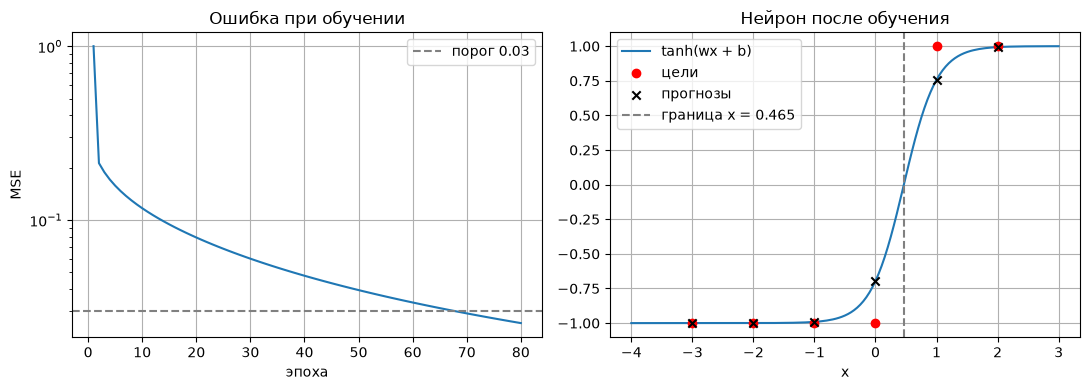

In [15]:
import matplotlib.pyplot as plt

w_final = trained_neuron.weight.data
b_final = trained_neuron.bias.data
boundary = -b_final / w_final
print("Эпоха, где ошибка впервые < 0.1:", next(i + 1 for i, l in enumerate(losses) if l < 0.1))
print("Эпоха, где ошибка впервые < 0.03:", next(i + 1 for i, l in enumerate(losses) if l < 0.03))
print("Граница x = -b/w:", boundary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(1, epochs + 1), losses)
axes[0].axhline(0.03, color="gray", linestyle="--", label="порог 0.03")
axes[0].set_yscale("log")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("MSE")
axes[0].set_title("Ошибка при обучении")
axes[0].legend()
axes[0].grid(True)

xs = [-4 + 0.05 * k for k in range(141)]
axes[1].plot(xs, [math.tanh(w_final * x + b_final) for x in xs], label="tanh(wx + b)")
axes[1].scatter(INPUTS, TARGETS, color="red", zorder=3, label="цели")
axes[1].scatter(INPUTS, final_predictions, color="black", marker="x", zorder=3, label="прогнозы")
axes[1].axvline(boundary, color="gray", linestyle="--", label=f"граница x = {boundary:.3f}")
axes[1].set_xlabel("x")
axes[1].set_title("Нейрон после обучения")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Интерпретация обучения.**

- Ошибка упала с $1.0$ в первой эпохе до $\approx 0.0256$ в последней, порог $0.03$ пройден. Самый большой скачок — на первом шаге: уже во второй эпохе $L \approx 0.2125$. Дальше спуск медленный: ниже $0.1$ ошибка опускается на 14-й эпохе, ниже $0.03$ — только на 68-й.
- После обучения $w \approx 1.850$, $b \approx -0.859$. Граница $x = -b/w \approx 0.465$ лежит между точками $x = 0$ (цель $-1$) и $x = 1$ (цель $1$), поэтому все шесть знаков верные и точность равна $1$.
- Хуже всего предсказаны две точки у границы: $\hat y(0) \approx -0.696$ и $\hat y(1) \approx 0.758$. Остальные почти в насыщении ($\hat y(-3) \approx -0.99999$, $\hat y(2) \approx 0.993$), и основная доля оставшейся ошибки приходится на эти две точки. Для них $1 - \hat y^2$ ещё заметно больше нуля, поэтому они и дают основной градиент на поздних эпохах.
- Ошибка дальше не падает быстро, потому что для $\hat y \to \pm1$ нужно $|z| \to \infty$: $\tanh$ никогда не достигает $\pm1$, а множитель $1 - \hat y^2$ у насыщенных точек почти ноль.

## Чек-лист

- [x] Пройдены все проверки из guide (все `assert` в ячейках выше выполнились без ошибок).
- [x] Градиент для `a * a + a` равен 5 при `a = 2`.
- [x] Численный и аналитический градиенты близки: $f'(0.37) \approx 2.283986$, ошибка порядка $10^{-10}$; для нейрона $g_w = -3$, $g_b \approx 0.6667$ совпали с разностью.
- [x] Финальная ошибка $\approx 0.0256 < 0.03$, точность равна 1.

Полный чек-лист и вопросы находятся в конце `lab_guide.pdf`.

### Полный чек-лист из guide

- [x] Могу объяснить, что хранит каждая вершина `Value`: `data`, `grad`, `parents`, `op`, `_backward`.
- [x] Проверил прямой проход сложения, умножения, отрицания, вычитания, степени и элементарных функций.
- [x] Получил градиент 5 для $a \cdot a + a$ при $a = 2$.
- [x] Сравнил градиент `Value` с центральной разностью.
- [x] Могу объяснить, как `Value`, `parents`, замыкания `_backward`, `visited` и `+=` вместе дают автоматическое дифференцирование.
- [x] Записал функцию потерь нейрона формулой: $L = \frac1n\sum (\tanh(wx_i + b) - y_i)^2$.
- [x] Получил ошибку меньше 0.03 и точность 1 после обучения.
- [x] Могу объяснить, почему вес и смещение — `Value`, а не `float`.

## Ответы на вопросы для самопроверки

**1. Почему $a$ в выражении $a \cdot a + a$ получает два вклада градиента?**
Объект `a` встречается в графе несколько раз: дважды как родитель умножения (`parents = (a, a)`) и ещё раз как слагаемое. По многомерному правилу цепочки производная — сумма по всем путям, поэтому каждое ребро прибавляет свой вклад через `+=`: $1$ от сложения и $2 + 2$ от умножения, итого $5 = 2a + 1$.

**2. Почему итоговая вершина получает начальный градиент 1?**
Потому что $g_J = \partial J / \partial J = 1$: изменение $J$ на $\Delta J$ меняет $J$ ровно на $\Delta J$. Без этой единицы все локальные правила умножали бы на ноль и все градиенты остались бы нулевыми.

**3. Почему локальное правило умножения использует значение второго множителя?**
Для $z = xy$ при фиксированном $y$ выражение равно $y$, умноженному на $x$, поэтому $\partial z / \partial x = y$. Отсюда `self.grad += result.grad * other.data` и наоборот для `other`.

**4. Почему нельзя обновить вес до вызова `backward`?**
Замыкания читают `data` в момент обратного прохода (например, `other.data` в умножении). Если поменять вес раньше, производная посчитается в новой точке, а граф построен для старой — градиент будет неверный. Поэтому в эпохе сначала `loss.backward()`, потом обновление.

**5. Почему выход $\tanh$ подходит для целей $-1$ и $1$?**
$\tanh$ принимает значения в интервале $(-1, 1)$ и монотонно растёт, поэтому знак выхода сразу даёт класс, а сами цели $\pm1$ — пределы функции. У нас прогнозы после обучения от $-0.99999$ до $0.993$.

**6. Каких возможностей промышленного autograd нет в этой реализации?**
Нет векторов, матриц и тензоров, пакетной обработки и broadcasting, вторых производных, производной по показателю степени, повторного использования графа, оптимизаторов (только ручной градиентный спуск), оптимизированных ядер и работы на GPU. Рекурсивный `build` может упереться в лимит рекурсии на длинной цепочке. `log` определён только при $x > 0$.

**7. Почему `visited` добавляет `a` в `topo` один раз, а $a \cdot a$ всё равно даёт два вклада?**
`visited` отвечает только за порядок обхода — каждая вершина вызывает свой `_backward` один раз. А вклады создаёт замыкание умножения: в нём две строки `self.grad += ...` и `other.grad += ...`, и при `a * a` обе указывают на один и тот же объект `a`, поэтому `a.grad` увеличивается дважды.

**8. Какие ссылки сохраняет замыкание `_backward` и почему обновление `parameter.data` должно идти после `loss.backward()`?**
Замыкание хранит ссылки на объекты `self`, `other` (родителей) и `result` (саму вершину), а не их числа. В момент вызова оно читает текущие `result.grad` и `data` родителей. Если поменять `parameter.data` до `backward`, замыкание прочитает новые значения вместо тех, что были в прямом проходе, поэтому сначала `backward`, потом обновление, а на следующей эпохе строится новый граф.